# Loading and Cleaning the Dataset

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel('../data/raw/data_million_.xlsx', engine='calamine')
print(df.shape)

(38124, 15)


In [3]:
df.head()

,Unnamed: 0,Company name Latin alphabet,Country ISO code,Consolidation code,Listing status,Operating revenue (Turnover) m USD 2025,Operating revenue (Turnover) m USD 2024,Operating revenue (Turnover) m USD 2023,Operating revenue (Turnover) m USD 2022,Operating revenue (Turnover) m USD 2021,Total assets m USD 2025,Total assets m USD 2024,Total assets m USD 2023,Total assets m USD 2022,Total assets m USD 2021
0,1.0,TRAFIGURA CONTROL HOLDINGS PTE. LTD.,SG,C2,Unlisted,240268.000,243202.000000,244280.000,318481.100000,231309.600000,79517.900,76943.800000,86505.100,98202.000000,90664.000000
1,2.0,TRAFIGURA GROUP PTE. LTD.,SG,C2,Unlisted,240268.000,243202.000000,244280.000,318481.100000,231309.600000,79493.900,76426.500000,83382.500,98066.300000,90065.700000
2,3.0,NVIDIA SINGAPORE PTE LTD,SG,U1,Unlisted,117774.690,66577.956000,43181.093,20786.815000,21612.757000,26896.486,11333.790000,6628.668,4153.001000,4294.814000
3,4.0,VITOL ASIA PTE LTD,SG,U1,Unlisted,93685.884,85250.900163,83465.374,118286.971245,70743.858449,9700.790,10935.822481,11426.306,12518.357473,13067.135194
4,5.0,WILMAR INTERNATIONAL LIMITED,SG,C1,Listed,70704.083,67772.985000,67715.457,73856.343000,66070.441000,65641.775,59572.170000,61808.692,60401.970000,58718.446000


In [4]:
# Checking for missing values
rev_cols = [col for col in df.columns if 'Operating revenue' in col]
asset_cols = [col for col in df.columns if 'Total assets' in col]
all_metric_cols = rev_cols + asset_cols

# Replace exact zeros (numeric or string) or common text placeholders with NaN
for col in all_metric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce') # Converts text placeholders to NaN
    df[col] = df[col].replace(0.0, np.nan)            # Converts numeric 0 to NaN

# Drop companies where ALL metric columns are missing because we need data 2021 through 2025.
df = df.dropna(subset=all_metric_cols, how='all')

# Display the remaining missing value summary
print(df.isna().sum())


Unnamed: 0                                     0
Company name Latin alphabet                    0
Country ISO code                               0
Consolidation code                             0
Listing status                                 0
Operating revenue (Turnover) m USD 2025    11176
Operating revenue (Turnover) m USD 2024    10728
Operating revenue (Turnover) m USD 2023    10586
Operating revenue (Turnover) m USD 2022     6368
Operating revenue (Turnover) m USD 2021     6824
Total assets m USD 2025                      342
Total assets m USD 2024                      250
Total assets m USD 2023                      225
Total assets m USD 2022                      186
Total assets m USD 2021                      212
dtype: int64


In [5]:
print(df.shape)

(37891, 15)


In [6]:
#Checking if ISO code is SG for all entries
(df['Country ISO code'] != "SG").sum()

np.int64(0)

In [7]:
#Number of public vs pvt firms and dropping delisted firms
print(df['Listing status'].value_counts())
df['Listing status'] = df['Listing status'].replace('Delisted', np.nan)
df = df.dropna(subset=['Listing status'])
df['Listing status'].value_counts()

Listing status
Unlisted    37192
Listed        490
Delisted      209
Name: count, dtype: int64


Listing status
Unlisted    37192
Listed        490
Name: count, dtype: int64

• C1 (Consolidated without companion): Consolidated financial statements (mother company integrating subsidiaries and branches) where no separate unconsolidated companion statement is available in Orbis.

• C2 (Consolidated with companion): Consolidated financial statements (mother company integrating subsidiaries and branches) where a separate unconsolidated companion statement is also available in Orbis.

• U1 (Unconsolidated without companion): Unconsolidated financial statements (showing only the single firm, not integrating subsidiaries or branches) where no separate consolidated companion statement is available in Orbis.

• U2 (Unconsolidated with companion): Unconsolidated financial statements (showing only the single firm) where a separate consolidated companion statement is also available in Orbis.


In [8]:
#Keep C1 and U1 and drop C2 and U2
df = df[df['Consolidation code'].isin(['C1', 'U1'])]
df['Consolidation code'].value_counts()

Consolidation code
U1    33231
C1      481
Name: count, dtype: int64

In [9]:
#Checking for duplicate names
print(f'Number of duplicated firms in the dataset: {df['Company name Latin alphabet'].duplicated().sum()}')
display(df[df['Company name Latin alphabet'].duplicated()])

Number of duplicated firms in the dataset: 5


,Unnamed: 0,Company name Latin alphabet,Country ISO code,Consolidation code,Listing status,Operating revenue (Turnover) m USD 2025,Operating revenue (Turnover) m USD 2024,Operating revenue (Turnover) m USD 2023,Operating revenue (Turnover) m USD 2022,Operating revenue (Turnover) m USD 2021,Total assets m USD 2025,Total assets m USD 2024,Total assets m USD 2023,Total assets m USD 2022,Total assets m USD 2021
482,483.0,SWIRE SHIPPING PTE. LTD.,SG,U1,Unlisted,1058.040000,1125.704000,1144.867887,1326.825117,804.487153,809.051000,830.454000,891.106185,1051.115757,961.176911
2912,2913.0,GLAXOCHEM PTE LTD,SG,U1,Unlisted,62.547850,67.109604,58.965344,16.041987,0.069857,1534.893431,1373.146825,1326.274508,1201.382303,1319.511546
6440,6441.0,YHS INTERNATIONAL PTE. LTD.,SG,U1,Unlisted,13.659175,14.008863,12.567645,15.049989,20.080872,71.119357,68.093919,64.432271,60.509379,59.671061
11156,11157.0,BRIDGETEK PTE. LTD.,SG,U1,Unlisted,3.794148,3.926229,5.986941,21.300957,6.671240,11.291730,12.302155,14.434448,13.702251,10.114960
36765,36766.0,EMERALD ENTERPRISE PTE. LTD.,SG,U1,Unlisted,NaN,NaN,NaN,NaN,NaN,227.961078,143.232941,0.000153,0.002953,NaN


In [10]:
name = "Company name Latin alphabet"
# Same-name pairs on U1 with near-identical values: keep first, log the drop
df = df.drop_duplicates(subset=[name], keep="first")
print(f'Number of duplicated firms in the dataset: {df[name].duplicated().sum()}')

Number of duplicated firms in the dataset: 0


In [11]:
# Save the cleaned company-level dataset.
df.to_csv("../data/processed/companies_cleaned_wide.csv",
    index=False
)

## Wide to Long

In [12]:
# Reshape the dataframe into a long format (one row per firm per year)
# Columns are in the format: 'Metric name bn USD YYYY'
data_long = pd.wide_to_long(
    df,
    stubnames=['Operating revenue (Turnover) m USD', 'Total assets m USD'],
    i=['Company name Latin alphabet', 'Country ISO code', 'Listing status', 'Consolidation code'],
    j='Year',
    sep=' '
).reset_index()

# Sort the values logically by company and year
data_long = data_long.sort_values(by=['Unnamed: 0', 'Year'])

# Display the long format dataframe
display(data_long.head())

,Company name Latin alphabet,Country ISO code,Listing status,Consolidation code,Year,Unnamed: 0,Operating revenue (Turnover) m USD,Total assets m USD
4,NVIDIA SINGAPORE PTE LTD,SG,Unlisted,U1,2021,3.0,21612.757,4294.814
3,NVIDIA SINGAPORE PTE LTD,SG,Unlisted,U1,2022,3.0,20786.815,4153.001
2,NVIDIA SINGAPORE PTE LTD,SG,Unlisted,U1,2023,3.0,43181.093,6628.668
1,NVIDIA SINGAPORE PTE LTD,SG,Unlisted,U1,2024,3.0,66577.956,11333.790
0,NVIDIA SINGAPORE PTE LTD,SG,Unlisted,U1,2025,3.0,117774.690,26896.486


In [13]:
data_long.shape

(168535, 8)

In [14]:
# Save the final company-year dataset used for tests and charts.
data_long.to_csv("../data/processed/company_year_panel.csv",
    index=False
)

## Creating Public vs Pvt Firms

In [15]:
#Grouping by public and pvt companies
public = data_long[data_long['Listing status'] == 'Listed']
private = data_long[data_long['Listing status'] == 'Unlisted']
print(f'Number of public firms across 5 years: {public.shape}')
print(f'Number of private firms across 5 year: {private.shape}')

Number of public firms across 5 years: (2395, 8)
Number of private firms across 5 year: (166140, 8)


For each of the five years, separate firms into public and private groups and create valid revenue and asset samples.

In [16]:
def summarise(df, col):
    s = df[col]
    return {
        'total': len(s),
        'missing': s.isna().sum(),
        'zero': (s == 0).sum(),
        'negative': (s < 0).sum(),
        'positive': (s > 0).sum(),
    }

rows = []
for y in range(2021, 2026):
    for label, df in [('Public', public), ('Private', private)]:
        d = df[df['Year'] == y]
        for var in ['Operating revenue (Turnover) m USD', 'Total assets m USD']:
            r = summarise(d, var)
            rows.append({'Year': y, 'Group': label, 'Variable': var, **r})

checks = pd.DataFrame(rows)

# Column totals across all rows
count_cols = ['missing', 'zero', 'negative', 'positive']
totals = checks[count_cols].sum()
total_row = pd.DataFrame([{'Year': 'Total', 'Group': '', 'Variable': '', **totals.to_dict()}])
checks_with_total = pd.concat([checks, total_row], ignore_index=True)

display(checks_with_total)

,Year,Group,Variable,total,missing,zero,negative,positive
0,2021,Public,Operating revenue (Turnover) m USD,479.0,2,0,0,477
1,2021,Public,Total assets m USD,479.0,0,0,0,479
2,2021,Private,Operating revenue (Turnover) m USD,33228.0,6267,0,155,26806
3,2021,Private,Total assets m USD,33228.0,207,0,6,33015
4,2022,Public,Operating revenue (Turnover) m USD,479.0,1,0,0,478
5,2022,Public,Total assets m USD,479.0,0,0,0,479
6,2022,Private,Operating revenue (Turnover) m USD,33228.0,5932,0,307,26989
7,2022,Private,Total assets m USD,33228.0,179,0,7,33042
8,2023,Public,Operating revenue (Turnover) m USD,479.0,1,0,0,478
9,2023,Public,Total assets m USD,479.0,0,0,0,479


* all 1,013 negative values are in the private group.
* Total assets: Negative values are almost certainly data errors. Under standard accounting, assets can’t be negative, so dropping them is reasonable. (31 entries)
* Operating revenue (982 negatives): Dropping them is reasonable for a size comparison, since negative turnover doesn’t measure firm size.
* Affected observations are about 0.5–0.9% of each year’s private sample, so the effect on medians should be small.



In [17]:
def clean(df, col, keep_negatives=False):
    s = df[col].dropna()
    return s if keep_negatives else s[s >= 0]

# Main spec: drop negatives
pub_rev  = clean(public[public['Year'] == 2025], 'Operating revenue (Turnover) m USD')
priv_rev = clean(private[private['Year'] == 2025], 'Operating revenue (Turnover) m USD')

# Robustness: keep negatives
pub_rev_all  = clean(public[public['Year'] == 2025], 'Operating revenue (Turnover) m USD', keep_negatives=True)
priv_rev_all = clean(private[private['Year'] == 2025], 'Operating revenue (Turnover) m USD', keep_negatives=True)

print("Median (drop neg):", pub_rev.median(), round(priv_rev.median(),4))
print("Median (keep neg):", pub_rev_all.median(), round(priv_rev_all.median(),4))

Median (drop neg): 63.288 1.752
Median (keep neg): 63.288 1.7158


Since the difference is negligible we take only the positive values of private firms.

In [18]:
rows = []
for y in range(2021, 2026):
    p = public[public['Year'] == y]
    q = private[private['Year'] == y]
    rows.append({
        'Year': y,
        'Public firms': len(p),
        'Public valid revenue': (p['Operating revenue (Turnover) m USD'] > 0).sum(),
        'Public valid assets': (p['Total assets m USD'] > 0).sum(),
        'Private firms': len(q),
        'Private valid revenue': (q['Operating revenue (Turnover) m USD'] > 0).sum(),
        'Private valid assets': (q['Total assets m USD'] > 0).sum(),
    })

sample_sizes = pd.DataFrame(rows)
display(sample_sizes)

,Year,Public firms,Public valid revenue,Public valid assets,Private firms,Private valid revenue,Private valid assets
0,2021,479,477,479,33228,26806,33015
1,2022,479,478,479,33228,26989,33042
2,2023,479,478,479,33228,23245,33010
3,2024,479,479,479,33228,23122,32987
4,2025,479,479,479,33228,22719,32902


# EDA

group sample sizes, medians, quartiles and interquartile ranges

In [19]:
panel = pd.read_csv("../data/processed/company_year_panel.csv")

measures = {
    'Operating revenue (Turnover) m USD': 'Revenue',
    'Total assets m USD': 'Total assets',
}
group_map = {'Listed': 'Public', 'Unlisted': 'Private'}

def valid(df, year, status, col):
    """Return the strictly positive, non-missing values for one year, group and measure."""
    return df.loc[
        (df['Year'] == year)
        & (df['Listing status'] == status)
        & (df[col] > 0),
        col,
    ]

In [20]:
rows = []
for year in range(2021, 2026):
    for col, label in measures.items():
        for status, group in group_map.items():
            s = valid(panel, year, status, col)

            # Quartiles: 25th, 50th (median) and 75th percentiles.
            q1, median, q3 = s.quantile([0.25, 0.5, 0.75])

            rows.append({
                'Year': year,
                'Measure': label,
                'Group': group,
                'Sample Size': len(s),
                'Median': round(median, 2),
                'Q1': round(q1, 2),
                'Q3': round(q3, 2),
                'IQR': round(q3 - q1, 2),   # IQR = Q3 - Q1
            })

eda_table = pd.DataFrame(rows)
display(eda_table)

descriptive_table = eda_table.sort_values(
    by=["Measure", "Year", "Group"]
)

# Save the descriptive-statistics table.
descriptive_table.to_csv(
    "../outputs/tables/descriptive_statistics.csv",
    index=False,
)

,Year,Measure,Group,Sample Size,Median,Q1,Q3,IQR
0,2021,Revenue,Public,477,57.32,17.83,185.10,167.27
1,2021,Revenue,Private,26806,1.03,0.16,6.14,5.97
2,2021,Total assets,Public,479,111.52,38.66,589.36,550.70
3,2021,Total assets,Private,33015,2.34,0.31,17.90,17.59
4,2022,Revenue,Public,478,64.92,18.89,190.66,171.78
5,2022,Revenue,Private,26989,1.20,0.20,7.12,6.92
6,2022,Total assets,Public,479,110.01,35.90,591.93,556.03
7,2022,Total assets,Private,33042,2.62,0.36,19.17,18.81
8,2023,Revenue,Public,478,64.33,17.60,208.61,191.01
9,2023,Revenue,Private,23245,1.61,0.33,8.15,7.82


## ECDF Visualisations

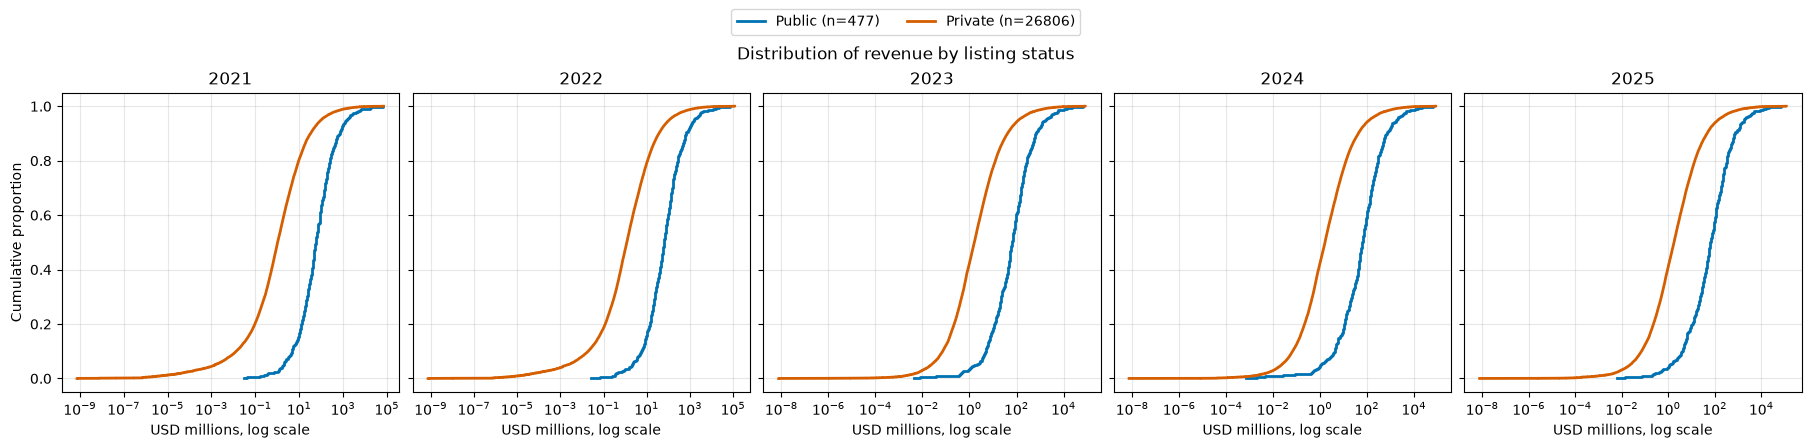

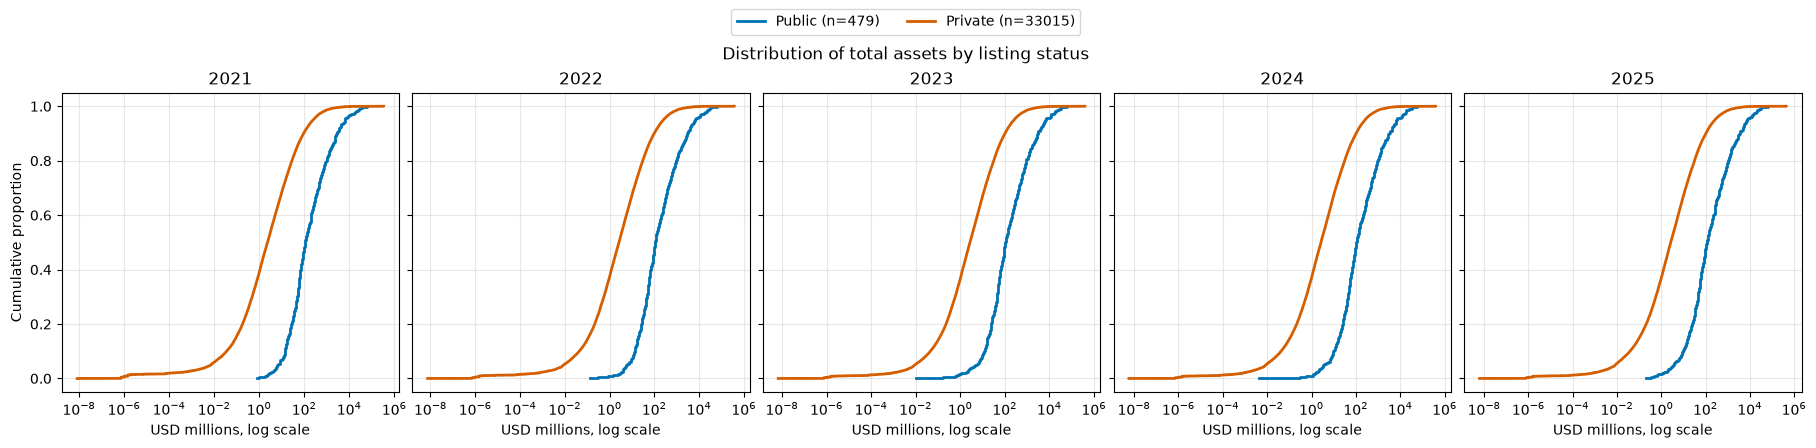

In [21]:
def ecdf(x):
    """Sorted values and their cumulative shares, for drawing a step plot."""
    x = np.sort(x)
    return x, np.arange(1, len(x) + 1) / len(x)

# Create one five-panel figure for revenue and another for assets.
for column_name, measure_name in measures.items():

    fig, axes = plt.subplots(
        nrows=1,
        ncols=5,
        figsize=(18, 4),
        sharey=True,
        constrained_layout=True,
    )

    # Make one panel for each year.
    for ax, year in zip(axes, [2021, 2022, 2023, 2024, 2025]):

        # Select positive public-company observations for this year.
        public_values = panel.loc[
            (panel["Year"] == year)
            & (panel["Listing status"] == "Listed")
            & (panel[column_name] > 0),
            column_name,
        ]

        # Select positive private-company observations for this year.
        private_values = panel.loc[
            (panel["Year"] == year)
            & (panel["Listing status"] == "Unlisted")
            & (panel[column_name] > 0),
            column_name,
        ]

        # Convert each group into ECDF coordinates.
        public_x, public_y = ecdf(public_values)
        private_x, private_y = ecdf(private_values)

        # Draw the public-company ECDF.
        ax.step(
            public_x,
            public_y,
            where="post",
            label=f"Public (n={len(public_values)})",
            color="#0072B2",
            linewidth=2,
        )

        # Draw the private-company ECDF.
        ax.step(
            private_x,
            private_y,
            where="post",
            label=f"Private (n={len(private_values)})",
            color="#D55E00",
            linewidth=2,
        )

        # A logarithmic scale makes smaller firms visible beside very large firms.
        ax.set_xscale("log")

        ax.set_title(year)
        ax.set_xlabel("USD millions, log scale")
        ax.grid(alpha=0.3)

    # Label the shared vertical axis.
    axes[0].set_ylabel("Cumulative proportion")

    # Put one shared legend above all five panels.
    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=2,
        bbox_to_anchor=(0.5, 1.10),
    )

    fig.suptitle(
        f"Distribution of {measure_name.lower()} by listing status"
    )

    # Create a simple filename.
    filename = measure_name.lower().replace(" ", "_")

    # Save the chart.
    plt.savefig(
        f"../outputs/figures/ecdf_{filename}.png",
        dpi=300,
        bbox_inches="tight",
    )

* Public firms are larger in every year, for both measures. The blue curve sits to the right of the orange curve across almost the whole range.
* The gap is widest in the middle of the distribution. The curves nearly meet at the top (the largest firms) and at the bottom (the very smallest), so the difference is mostly in the typical firm.
* Public firms are more tightly grouped. The blue curves are steep. Most public firms fall within about two orders of magnitude, while the orange curves are spread out. Private firms cover a much wider range of sizes.
* Private firms have a long low tail. The flat part at the far left shows that a small number of private firms report tiny values.

## Box plots

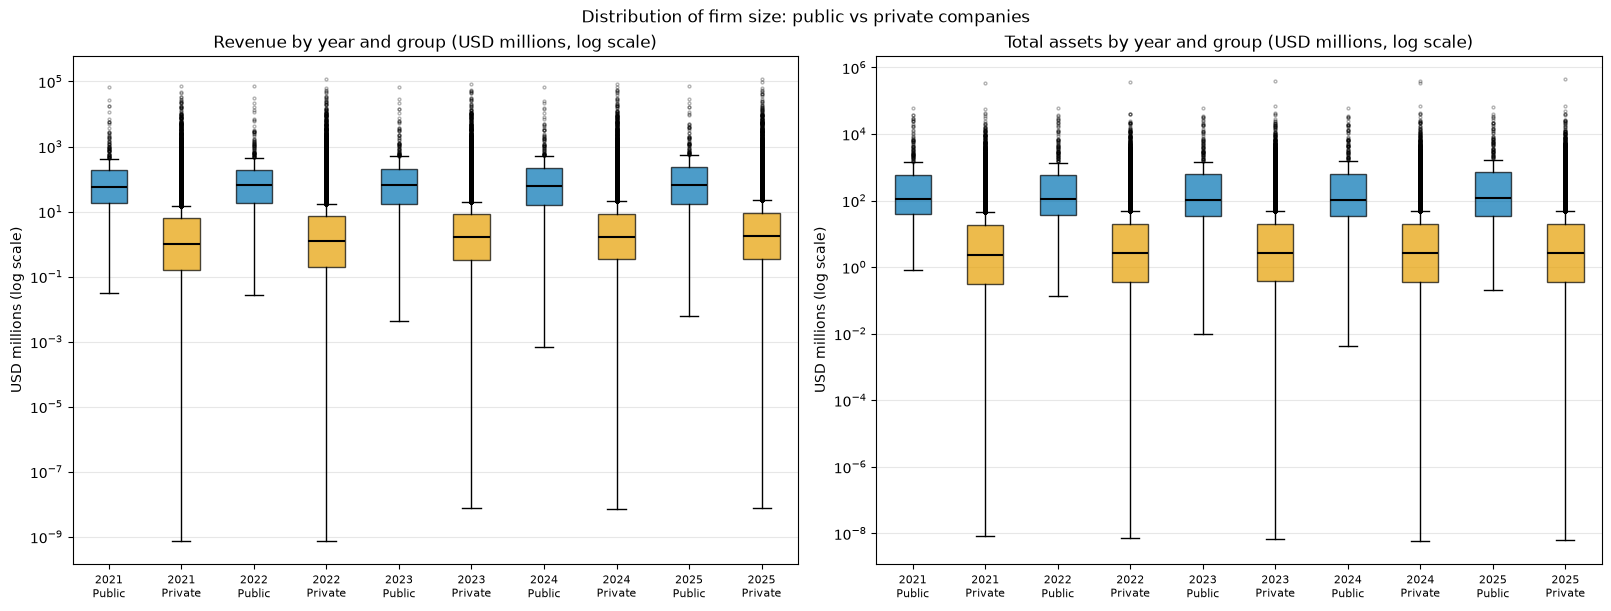

In [22]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6), constrained_layout=True)
colour_map = {'Public': '#0072B2', 'Private': '#E69F00'}

for ax, (col, label) in zip(axes, measures.items()):
    data, tick_labels, colours = [], [], []

    for year in range(2021, 2026):
        for status, group in group_map.items():
            s = valid(panel, year, status, col)
            data.append(s.to_numpy())
            tick_labels.append(f"{year}\n{group}")
            colours.append(colour_map[group])

    bp = ax.boxplot(
        data,
        patch_artist=True,
        flierprops=dict(marker='o', markersize=2, alpha=0.3),
        medianprops=dict(color='black', linewidth=1.5),
    )
    for patch, colour in zip(bp['boxes'], colours):
        patch.set_facecolor(colour)
        patch.set_alpha(0.7)

    ax.set_yscale('log')   # values span many orders of magnitude
    ax.set_xticks(range(1, len(tick_labels) + 1))
    ax.set_xticklabels(tick_labels, fontsize=8)
    ax.set_title(f"{label} by year and group (USD millions, log scale)")
    ax.set_ylabel("USD millions (log scale)")
    ax.grid(axis='y', alpha=0.3)

fig.suptitle("Distribution of firm size: public vs private companies")
plt.savefig("../outputs/figures/eda_boxplots_by_year_group.png", dpi=300, bbox_inches="tight")
plt.show()

* Public firms are much larger in both measures.
  * Revenue: the public median is roughly USD 50 to 100 million. The private median is around USD 1 to 2 million, so public firms are tens of times larger.
  * Total assets: the public median is roughly USD 100 to 150 million. The private median is about USD 2 to 3 million
* The medians and box positions change very little from 2021 to 2025. The public-private gap is a persistent feature of the data, not a result of one unusual year.
* Both groups have many outliers above the upper whisker. For private firms the outliers form a solid black band, because there are about 27,000 to 33,000 of them. This reflects the imbalance in the sample size, private (33015) vs public firms (479).
* This justifies the use of median to generate 95% Bootstrap Confidence intervals, as medians are unafffected by extreme values.

# KS Test

For Revenue:

*   Null hypothesis (H₀): The distribution of revenue is the same for public and private firms in that year. $$F_{\text{public}}(x) = F_{\text{private}}(x) \quad \text{for all } x$$
*   Alternative hypothesis (H₁): The distributions differ. Formally,$$F_{\text{public}}(x) \neq F_{\text{private}}(x) \quad \text{for at least one value of } x$$


For Total Assets:

*   Null hypothesis (H₀): The distribution of total assets is the same for public and private firms in that year. Formally, $$F_{\text{public}}(x) = F_{\text{private}}(x) \quad \text{for all } x$$

*   Alternative hypothesis (H₁): The distributions differ. Formally, $$F_{\text{public}}(x) \neq F_{\text{private}}(x) \quad \text{for at least one value of } x$$

In [23]:
ks_results = []
for year in range(2021, 2026):
    for col, label in measures.items():
        # Valid values only: strictly positive, non-missing (NaN > 0 is False)
        pub = public.loc[(public['Year'] == year) & (public[col] > 0), col].to_numpy()
        pri = private.loc[(private['Year'] == year) & (private[col] > 0), col].to_numpy()

        res = ks_2samp(pub, pri)  # two-sided by default
        ks_results.append({
            'Year': year,
            'Measure': label,
            'n_public': len(pub),
            'n_private': len(pri),
            'D': res.statistic,
            'p_value': res.pvalue,
        })

ks_table = pd.DataFrame(ks_results)

# Save the unrounded results for the final report.
ks_table.to_csv("../data/processed/ks_table.csv",index=False)

display(ks_table)

,Year,Measure,n_public,n_private,D,p_value
0,2021,Revenue,477,26806,0.646744,6.940420e-192
1,2021,Total assets,479,33015,0.632738,1.062517e-183
2,2022,Revenue,478,26989,0.639384,2.513027e-187
3,2022,Total assets,479,33042,0.610460,1.976604e-169
4,2023,Revenue,478,23245,0.597745,2.767334e-160
5,2023,Total assets,479,33010,0.600380,3.057818e-163
6,2024,Revenue,479,23122,0.594240,1.540421e-158
7,2024,Total assets,479,32987,0.587860,8.934752e-156
8,2025,Revenue,479,22719,0.579093,9.816681e-150
9,2025,Total assets,479,32902,0.581877,2.723755e-152


Every p-value is far below 0.001, so the null is rejected for all 10 tests. D falls from 0.647 to 0.579 for revenue and from 0.633 to 0.582 for total assets, so the distributions are very different.
Because the sample sizes are so unequal (about 479 public firms versus 23,000 to 33,000 private firms), the p-values are very small, and the test will detect even minor differences.

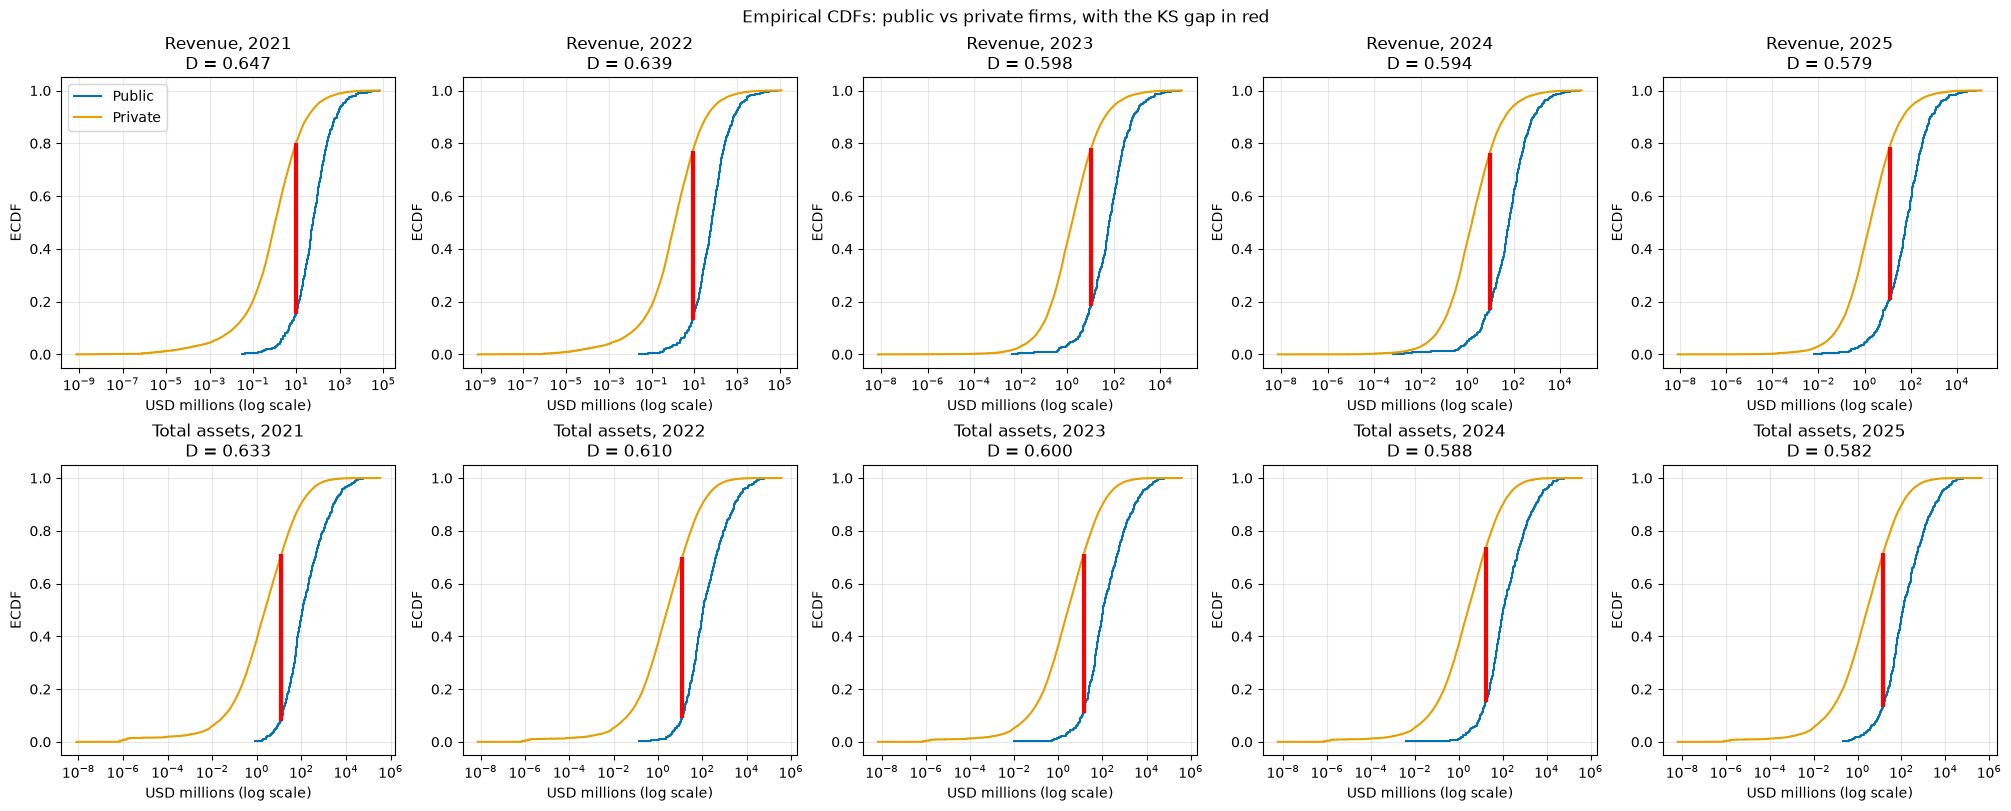

In [169]:
ks_table = pd.read_csv("../data/processed/ks_table.csv")

def ks_gap_location(a, b):
    """Return the x-value and the two ECDF heights where the gap is largest.
    Used only to place the red bar; D itself comes from ks_table."""
    grid = np.union1d(a, b)
    Fa = np.searchsorted(np.sort(a), grid, side='right') / len(a)
    Fb = np.searchsorted(np.sort(b), grid, side='right') / len(b)
    i = np.abs(Fa - Fb).argmax()
    return grid[i], Fa[i], Fb[i]

years = range(2021, 2026)
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(20, 8), constrained_layout=True)

for r, (col, label) in enumerate(measures.items()):
    for c, year in enumerate(years):
        ax = axes[r, c]

        a = valid(panel, year, 'Listed', col).to_numpy()    # public
        b = valid(panel, year, 'Unlisted', col).to_numpy()  # private

        # Read D for this year and measure from the saved table.
        D = ks_table.loc[
            (ks_table['Year'] == year) & (ks_table['Measure'] == label), 'D'
        ].item()

        # Find where the gap is largest, for the red bar.
        x_star, Fa, Fb = ks_gap_location(a, b)

        # Check that the gap at that point matches the saved D.
        assert np.isclose(abs(Fa - Fb), D), f"D mismatch for {label}, {year}"

        xa, ya = ecdf(a)
        xb, yb = ecdf(b)
        ax.step(xa, ya, where='post', color='#0072B2', label='Public')
        ax.step(xb, yb, where='post', color='#E69F00', label='Private')

        # Red bar: the size of the KS gap at the point where it is largest.
        ax.vlines(x_star, min(Fa, Fb), max(Fa, Fb), color='red', linewidth=3)

        ax.set_xscale('log')  # values span several orders of magnitude
        ax.set_title(f"{label}, {year}\nD = {D:.3f}")
        ax.set_xlabel("USD millions (log scale)")
        ax.set_ylabel("ECDF")
        ax.grid(alpha=0.3)

axes[0, 0].legend()
fig.suptitle("Empirical CDFs: public vs private firms, with the KS gap in red")

plt.savefig("../outputs/figures/ks_ecdf_gap.png", dpi=300, bbox_inches="tight")
plt.show()

* The largest difference is in the typical firm, around USD 10 to 20 million.
    The gap is almost always near this threshold. At that size, about 70–80% of private firms are smaller, while only 8–21% of public firms are.
* The two distributions differ across almost the whole range by around 60%.
    A D of about 0.6 means the two groups differ by roughly 60 percentage points at their most separated point, which is a large difference for two distributions.

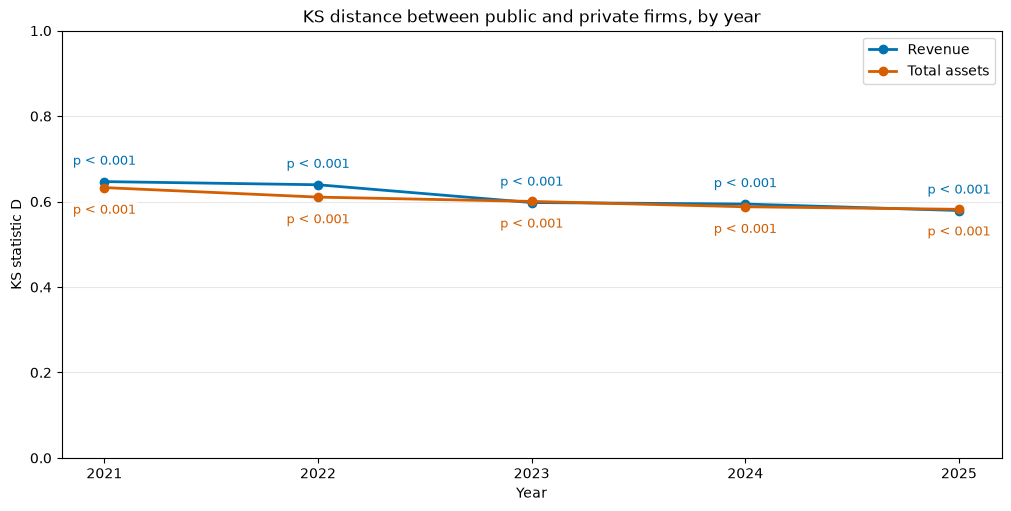

In [24]:
styles = {
    'Revenue':      {'colour': '#0072B2', 'offset': (0, 10),  'va': 'bottom'},
    'Total assets': {'colour': '#D55E00', 'offset': (0, -12), 'va': 'top'},
}

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)

for label, style in styles.items():
    sub = ks_table[ks_table['Measure'] == label].sort_values('Year')
    ax.plot(sub['Year'], sub['D'], marker='o', linewidth=2,
            color=style['colour'], label=label)

    for _, row in sub.iterrows():
        p_text = "p < 0.001" if row['p_value'] < 0.001 else f"p = {row['p_value']:.3f}"
        ax.annotate(
            p_text,
            (row['Year'], row['D']),
            textcoords='offset points',
            xytext=style['offset'],
            ha='center',
            va=style['va'],
            fontsize=9,
            color=style['colour'],
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='none', alpha=0.8),
        )

ax.set_title("KS distance between public and private firms, by year")
ax.set_xlabel("Year")
ax.set_ylabel("KS statistic D")
ax.set_xticks(sorted(ks_table['Year'].unique()))
ax.set_ylim(0, 1)
ax.grid(axis='y', alpha=0.3)
ax.legend(loc='upper right')

plt.savefig("../outputs/figures/ks_statistic_by_year.png", dpi=300, bbox_inches="tight")
plt.show()

* Both Revenue and Total assets follow the same pattern.
    D starts near 0.65 in 2021, falls to about 0.58 by 2025, and the two lines nearly converge by 2023. Revenue starts slightly higher, at about 0.647 against 0.633 for total assets, and the lines cross over in 2023. After that they are close together, and the difference between them is small
* The fall from 2021 to 2025 is about 0.06 to 0.07, a small change compared with the overall separation. The distributions are converging slowly, not coming together.
* Every test is significant at the 0.001 level, which indicates that the distributions remain clearly different across the full period.

# Bootstrap Annual Median Difference `D`

In [25]:
B = 10_000        # bootstrap replications
SEED = 2026         # fixed seed for reproducibility
CHUNK = 200       # resample in blocks to keep memory bounded
rng = np.random.default_rng(SEED)

boot_rows = []
for year in range(2021, 2026):
    for col, label in measures.items():
        # Valid values only: strictly positive, non-missing
        a = public.loc[(public['Year'] == year) & (public[col] > 0), col].to_numpy()
        b = private.loc[(private['Year'] == year) & (private[col] > 0), col].to_numpy()

        point = np.median(a) - np.median(b)

        # Resample each group with replacement, then take the median difference
        boot = np.empty(B)
        for start in range(0, B, CHUNK):
            k = min(CHUNK, B - start)
            boot_a = a[rng.integers(0, len(a), size=(k, len(a)))]
            boot_b = b[rng.integers(0, len(b), size=(k, len(b)))]
            boot[start:start + k] = np.median(boot_a, axis=1) - np.median(boot_b, axis=1)

        ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

        boot_rows.append({
            'Year': year,
            'Measure': label,
            'n_public': len(a),
            'n_private': len(b),
            'M_public': np.median(a),
            'M_private': np.median(b),
            'Difference': point,
            'CI_low_95': ci_low,
            'CI_high_95': ci_high,
        })

boot_table = pd.DataFrame(boot_rows)

# Save the unrounded results for charts and the final report
boot_table.to_csv("../data/processed/boot_table.csv",index=False)

display(boot_table.round(4))

,Year,Measure,n_public,n_private,M_public,M_private,Difference,CI_low_95,CI_high_95
0,2021,Revenue,477,26806,57.3182,1.0332,56.2850,46.0276,70.6788
1,2021,Total assets,479,33015,111.5177,2.3388,109.1789,87.4137,145.3780
2,2022,Revenue,478,26989,64.9236,1.1986,63.7250,52.7951,75.6246
3,2022,Total assets,479,33042,110.0136,2.6245,107.3890,89.1750,137.3991
4,2023,Revenue,478,23245,64.3275,1.6061,62.7214,52.3847,80.1035
5,2023,Total assets,479,33010,104.5200,2.7255,101.7945,86.6938,133.8436
6,2024,Revenue,479,23122,63.1302,1.6330,61.4972,49.8970,75.6470
7,2024,Total assets,479,32987,105.7340,2.6560,103.0781,84.1621,135.7391
8,2025,Revenue,479,22719,63.2880,1.7520,61.5360,52.8684,83.1512
9,2025,Total assets,479,32902,118.9756,2.6853,116.2903,91.6204,138.1315


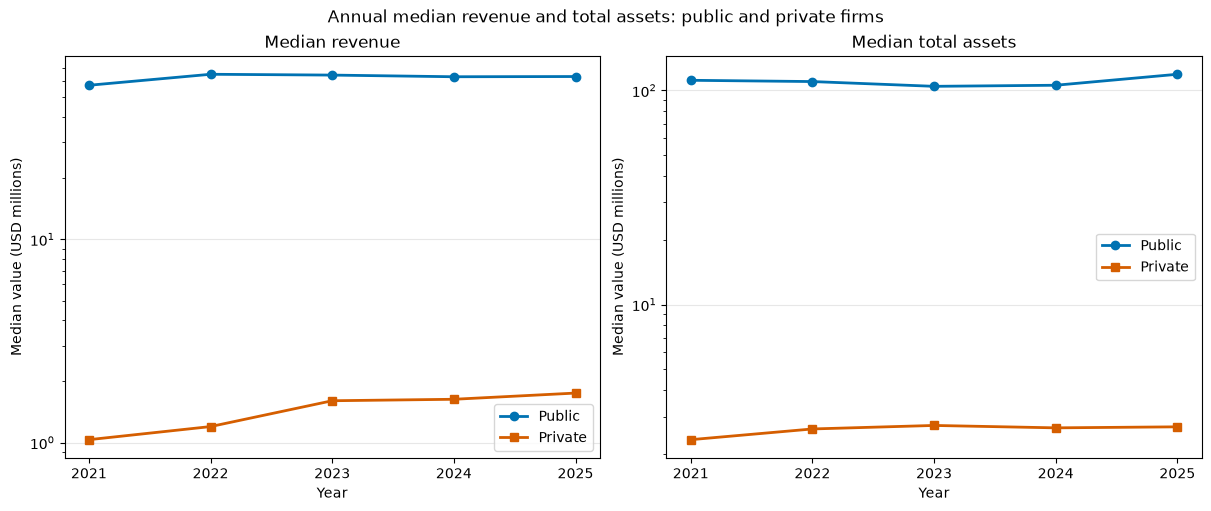

In [26]:
boot_table = pd.read_csv("../data/processed/boot_table.csv")

# Create two chart panels: one for revenue and one for total assets.
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(12, 5),
    constrained_layout=True,
)

# Create one chart for each financial measure.
for ax, measure in zip(axes, ["Revenue", "Total assets"]):

    # Keep only rows for the current measure.
    subset = boot_table[
        boot_table["Measure"] == measure
    ].sort_values("Year")

    # Plot public-company annual medians.
    ax.plot(
        subset["Year"],
        subset["M_public"],
        label="Public",
        color="#0072B2",
        marker="o",
        linewidth=2,
    )

    # Plot private-company annual medians.
    ax.plot(
        subset["Year"],
        subset["M_private"],
        label="Private",
        color="#D55E00",
        marker="s",
        linewidth=2,
    )

    # Add labels and styling.
    ax.set_title(f"Median {measure.lower()}")
    ax.set_xlabel("Year")
    ax.set_yscale('log')
    ax.set_ylabel("Median value (USD millions)")
    ax.set_xticks([2021, 2022, 2023, 2024, 2025])
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

fig.suptitle(
    "Annual median revenue and total assets: public and private firms"
)

# Save a high-quality image and a PDF version.
# Save the figure.
plt.savefig(
    "../outputs/figures/median_line_charts(log).png",
    dpi=300,
    bbox_inches="tight",
)

* The typical public firm is roughly 35 to 60 times larger than the typical private firm.
    Public median revenue is around USD 57 to 65 million, against roughly USD 1 to 2 million for private firms. The ratio is about 57 in 2021 and about 35 in 2025.

    For total assets, the public median is around USD 105 to 120 million, against about USD 2.5 million for private firms, a ratio of roughly 45 to 50. This matches the box plots and the bootstrap differences, which were all positive.

* Public medians are stable, while private medians rise slightly.
    Public revenue jumps from about 57 to 65 between 2021 and 2022, then stays near 63. Public total assets dip to about 104 in 2023 and recover to about 119 in 2025. These movements are modest. 
    
    Private revenue rises steadily, from about 1.0 to 1.8, which is almost a doubling. Private assets stay roughly flat at about 2.5.

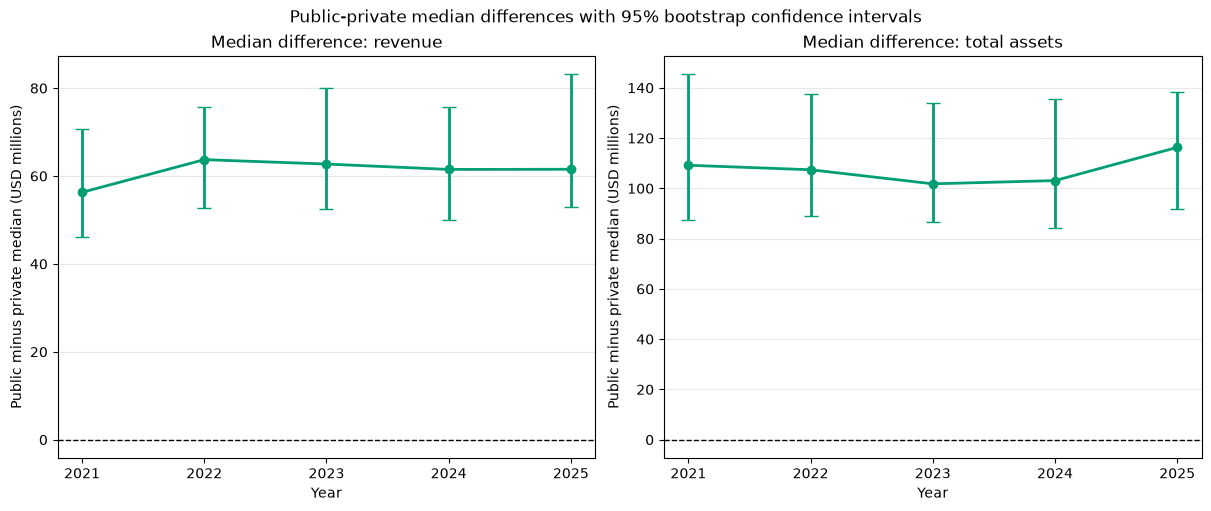

In [27]:
# Create two chart panels.
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(12, 5),
    constrained_layout=True,
)

# Create one confidence-interval chart for each measure.
for ax, measure in zip(axes, ["Revenue", "Total assets"]):

    # Keep only the rows for this measure.
    subset = boot_table[
        boot_table["Measure"] == measure
    ].sort_values("Year")

    # Calculate the lower and upper error-bar lengths.
    lower_error = subset["Difference"] - subset["CI_low_95"]
    upper_error = subset["CI_high_95"] - subset["Difference"]

    # Plot the median difference and its 95% confidence interval.
    ax.errorbar(
        subset["Year"],
        subset["Difference"],
        yerr=[lower_error, upper_error],
        fmt="o-",
        color="#009E73",
        linewidth=2,
        capsize=5,
    )

    # Add a line showing zero difference between groups.
    ax.axhline(
        y=0,
        color="black",
        linestyle="--",
        linewidth=1,
    )

    # Add labels and styling.
    ax.set_title(f"Median difference: {measure.lower()}")
    ax.set_xlabel("Year")
    ax.set_ylabel("Public minus private median (USD millions)")
    ax.set_xticks([2021, 2022, 2023, 2024, 2025])
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Public-private median differences with 95% bootstrap confidence intervals"
)

# Save the figure.
plt.savefig(
    "../outputs/figures/median_difference_confidence_intervals.png",
    dpi=300,
    bbox_inches="tight",
)

Every confidence interval is above zero, so the public median is larger than the private median in every year and for both measures. The gap is about 60 million USD for revenue and about 100 million USD for total assets, and it is stable across years.

These medians are for firms with positive values only. The private median is very small because many private firms are tiny, so the medians are sensitive to the zero-value exclusion.